# Tutorial answers, Q3: call centre (M/M/c)

8-minute calls; 12, 18 and 8.4 calls per hour; target: 80% of callers wait less than 2 minutes.

*Original script: `5 Source Files/Python/Q3_Call_Center.py` (kept unchanged). Same code, split into steps; the charts are drawn in one cell, and a replication check is added at the end (erratum C6). Run the cells in order; the first cell installs SimPy. Runs in the browser and in Jupyter on your own computer.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install simpy

In [2]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

**Global data collection.**

In [3]:
# Global data collection
wait_times = []
system_times = []

**`caller`** (function): Caller arrives, waits for agent, gets served, and leaves.

In [4]:
def caller(env, name, agents, service_rate):
    """Caller arrives, waits for agent, gets served, and leaves."""
    arrival_time = env.now
    
    with agents.request() as request:
        yield request
        
        # Record wait time
        wait_time = env.now - arrival_time
        wait_times.append(wait_time)
        
        # Service time (call handling time - exponential)
        service_time = random.expovariate(service_rate)
        yield env.timeout(service_time)
        
        # Record total system time
        system_time = env.now - arrival_time
        system_times.append(system_time)

**`caller_generator`** (function): Generate callers arriving at the call center.

In [5]:
def caller_generator(env, agents, arrival_rate, service_rate):
    """Generate callers arriving at the call center."""
    caller_number = 0
    while True:
        # Wait for next caller
        yield env.timeout(random.expovariate(arrival_rate))
        
        caller_number += 1
        env.process(caller(env, f"Caller {caller_number}", agents, service_rate))

**`run_simulation`** (function): Run a single simulation and return statistics.

In [6]:
def run_simulation(num_agents, arrival_rate, service_rate, sim_time, random_seed=42):
    """Run a single simulation and return statistics."""
    
    # Reset global data
    global wait_times, system_times
    wait_times = []
    system_times = []
    
    # Setup
    random.seed(random_seed)
    env = simpy.Environment()
    agents = simpy.Resource(env, capacity=num_agents)
    
    # Start generator
    env.process(caller_generator(env, agents, arrival_rate, service_rate))
    
    # Run simulation
    env.run(until=sim_time)
    
    # Calculate statistics
    total_callers = len(wait_times)
    avg_wait = np.mean(wait_times) if wait_times else 0
    max_wait = max(wait_times) if wait_times else 0
    
    # Service level: percentage waiting < 2 minutes
    callers_under_2min = sum(1 for w in wait_times if w < 2)
    pct_under_2min = 100 * callers_under_2min / total_callers if total_callers > 0 else 0
    
    # Calculate utilization
    utilization = arrival_rate / (num_agents * service_rate)
    
    return {
        'num_agents': num_agents,
        'utilization': utilization,
        'total_callers': total_callers,
        'avg_wait': avg_wait,
        'max_wait': max_wait,
        'pct_under_2min': pct_under_2min,
        'meets_target': pct_under_2min >= 80
    }

**Simulation parameters.**

In [7]:
# Simulation parameters
SIM_TIME = 480  # 8 hours in minutes
SERVICE_TIME_MEAN = 8  # minutes
SERVICE_RATE = 1 / SERVICE_TIME_MEAN  # calls per minute per agent

**Three time periods with different arrival rates.**

In [8]:
# Three time periods with different arrival rates
periods = {
    'Normal Hours': {'arrival_rate': 12/60, 'description': '12 calls/hour'},
    'Peak Hours': {'arrival_rate': 18/60, 'description': '18 calls/hour (50% higher)'},
    'Off-Peak Hours': {'arrival_rate': 8.4/60, 'description': '8.4 calls/hour (30% lower)'}
}

**Agent configurations to test.**

In [9]:
# Agent configurations to test
agent_configs = [2, 3, 4, 5]

print("="*90)
print("CALL CENTER CAPACITY PLANNING (M/M/c QUEUE)")
print("="*90)
print(f"Average call handling time: {SERVICE_TIME_MEAN} minutes")
print(f"Simulation time: {SIM_TIME} minutes (8 hours)")
print(f"Service level target: 80% of callers wait < 2 minutes")
print()

all_results = {}

for period_name, period_data in periods.items():
    print(f"\n{'='*90}")
    print(f"{period_name.upper()}: {period_data['description']}")
    print(f"{'='*90}")
    
    arrival_rate = period_data['arrival_rate']
    results = []
    
    for num_agents in agent_configs:
        stats = run_simulation(num_agents, arrival_rate, SERVICE_RATE, SIM_TIME)
        results.append(stats)
        
        meets = "✓ MEETS TARGET" if stats['meets_target'] else "✗ BELOW TARGET"
        print(f"\n{num_agents} Agents:")
        print(f"  Utilization (ρ): {stats['utilization']:.3f}")
        print(f"  Total callers: {stats['total_callers']}")
        print(f"  Average wait: {stats['avg_wait']:.2f} minutes")
        print(f"  Maximum wait: {stats['max_wait']:.2f} minutes")
        print(f"  % waiting < 2 min: {stats['pct_under_2min']:.1f}% {meets}")
    
    # Find minimum agents needed
    meeting_target = [r for r in results if r['meets_target']]
    if meeting_target:
        min_agents = min(meeting_target, key=lambda x: x['num_agents'])
        print(f"\n>>> Minimum agents needed: {min_agents['num_agents']} (achieves {min_agents['pct_under_2min']:.1f}%)")
    else:
        print(f"\n>>> WARNING: Target not met with up to {max(agent_configs)} agents!")
    
    all_results[period_name] = results

CALL CENTER CAPACITY PLANNING (M/M/c QUEUE)
Average call handling time: 8 minutes
Simulation time: 480 minutes (8 hours)
Service level target: 80% of callers wait < 2 minutes


NORMAL HOURS: 12 calls/hour

2 Agents:
  Utilization (ρ): 0.800
  Total callers: 96
  Average wait: 12.81 minutes
  Maximum wait: 35.74 minutes
  % waiting < 2 min: 22.9% ✗ BELOW TARGET

3 Agents:
  Utilization (ρ): 0.533
  Total callers: 106
  Average wait: 3.05 minutes
  Maximum wait: 27.06 minutes
  % waiting < 2 min: 67.9% ✗ BELOW TARGET

4 Agents:
  Utilization (ρ): 0.400
  Total callers: 108
  Average wait: 0.15 minutes
  Maximum wait: 3.29 minutes
  % waiting < 2 min: 97.2% ✓ MEETS TARGET

5 Agents:
  Utilization (ρ): 0.320
  Total callers: 106
  Average wait: 0.02 minutes
  Maximum wait: 2.60 minutes
  % waiting < 2 min: 99.1% ✓ MEETS TARGET

>>> Minimum agents needed: 4 (achieves 97.2%)

PEAK HOURS: 18 calls/hour (50% higher)

2 Agents:
  Utilization (ρ): 1.200
  Total callers: 123
  Average wait: 20.79

**Staffing recommendations.**

In [10]:
# Staffing recommendations
print("\n" + "="*90)
print("STAFFING RECOMMENDATIONS")
print("="*90)

recommendations = {}
for period_name, results in all_results.items():
    meeting_target = [r for r in results if r['meets_target']]
    if meeting_target:
        min_agents = min(meeting_target, key=lambda x: x['num_agents'])
        recommendations[period_name] = min_agents['num_agents']
        print(f"\n{period_name}:")
        print(f"  Recommended agents: {min_agents['num_agents']}")
        print(f"  Expected utilization: {min_agents['utilization']:.1%}")
        print(f"  Service level achieved: {min_agents['pct_under_2min']:.1f}%")
    else:
        recommendations[period_name] = max(agent_configs)
        print(f"\n{period_name}:")
        print(f"  WARNING: Need more than {max(agent_configs)} agents to meet target")


STAFFING RECOMMENDATIONS

Normal Hours:
  Recommended agents: 4
  Expected utilization: 40.0%
  Service level achieved: 97.2%

Peak Hours:
  Recommended agents: 5
  Expected utilization: 48.0%
  Service level achieved: 96.4%

Off-Peak Hours:
  Recommended agents: 3
  Expected utilization: 37.3%
  Service level achieved: 90.9%


**Create summary table.**

In [11]:
# Create summary table
print("\n" + "="*90)
print("SUMMARY TABLE")
print("="*90)
print(f"{'Period':<20} {'Arrival Rate':<15} {'Min Agents':<12} {'Comments':<30}")
print("-"*90)
for period_name in periods.keys():
    arr_rate = periods[period_name]['arrival_rate'] * 60
    min_agents = recommendations.get(period_name, '?')
    
    if period_name in all_results:
        meeting = [r for r in all_results[period_name] if r['meets_target']]
        if meeting:
            comment = f"Achieves {meeting[0]['pct_under_2min']:.1f}% service level"
        else:
            comment = "Target not met - need more agents"
    else:
        comment = ""
    
    print(f"{period_name:<20} {arr_rate:<15.1f} {min_agents!s:<12} {comment:<30}")


SUMMARY TABLE
Period               Arrival Rate    Min Agents   Comments                      
------------------------------------------------------------------------------------------
Normal Hours         12.0            4            Achieves 97.2% service level  
Peak Hours           18.0            5            Achieves 96.4% service level  
Off-Peak Hours       8.4             3            Achieves 90.9% service level  


**Charts.** All four panels are drawn in this one cell, so they show in the browser too (the original script draws them over several steps). The picture is also saved as a PNG next to the notebook.


Visualization saved as 'Q3_Call_Center_Results.png'


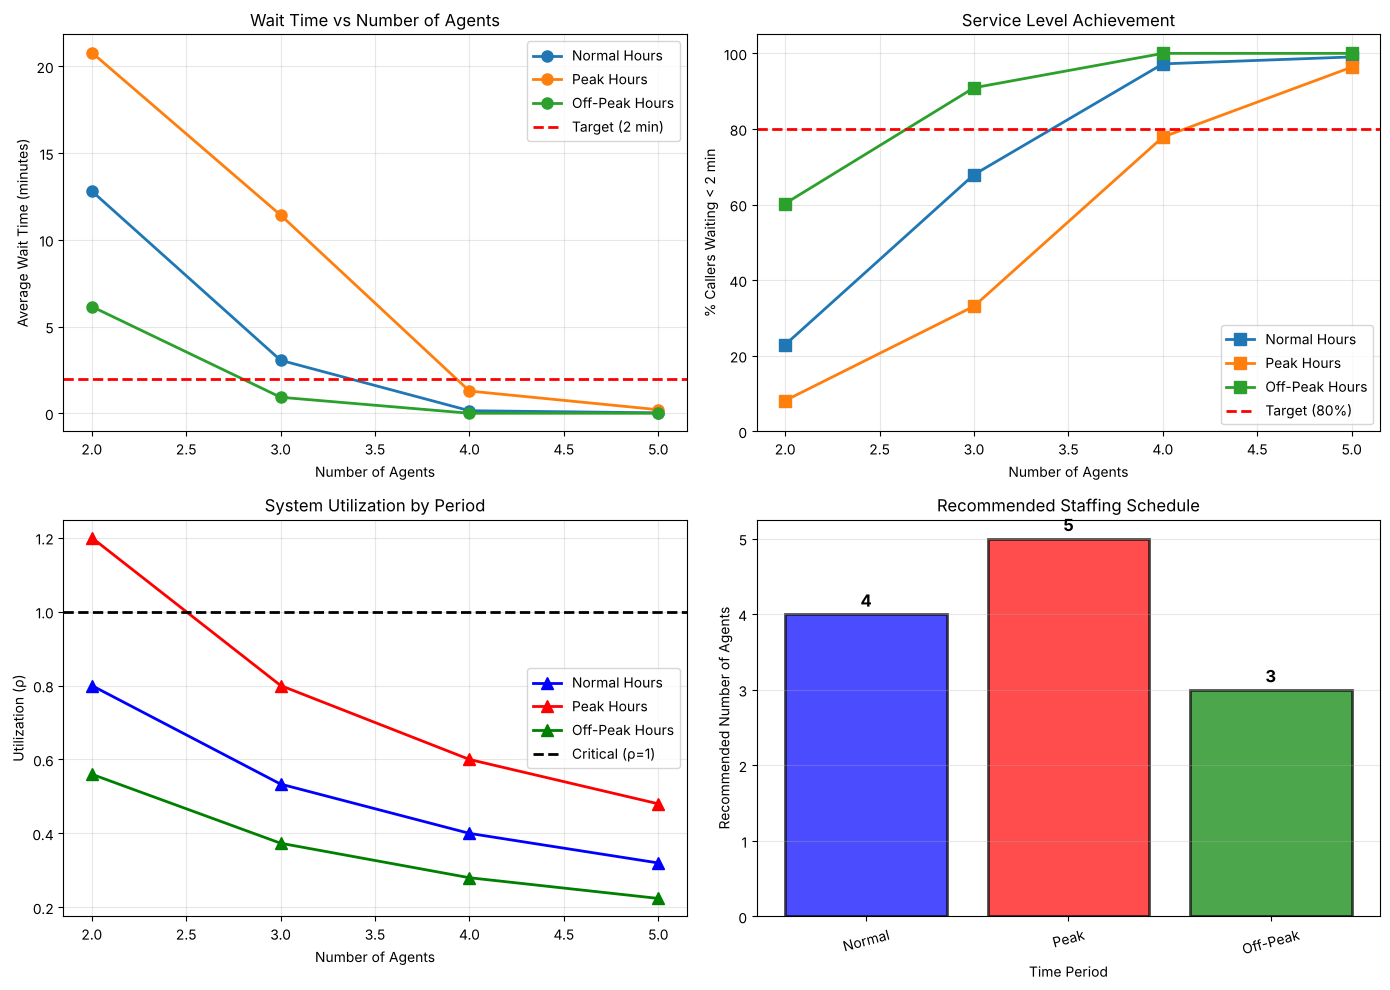

In [12]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Average wait time vs agents for all periods
for period_name, results in all_results.items():
    agents = [r['num_agents'] for r in results]
    avg_waits = [r['avg_wait'] for r in results]
    axes[0, 0].plot(agents, avg_waits, marker='o', linewidth=2, markersize=8, label=period_name)

axes[0, 0].axhline(y=2, color='red', linestyle='--', linewidth=2, label='Target (2 min)')
axes[0, 0].set_xlabel('Number of Agents')
axes[0, 0].set_ylabel('Average Wait Time (minutes)')
axes[0, 0].set_title('Wait Time vs Number of Agents')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Service level (% under 2 min) vs agents
for period_name, results in all_results.items():
    agents = [r['num_agents'] for r in results]
    pct_under_2 = [r['pct_under_2min'] for r in results]
    axes[0, 1].plot(agents, pct_under_2, marker='s', linewidth=2, markersize=8, label=period_name)

axes[0, 1].axhline(y=80, color='red', linestyle='--', linewidth=2, label='Target (80%)')
axes[0, 1].set_xlabel('Number of Agents')
axes[0, 1].set_ylabel('% Callers Waiting < 2 min')
axes[0, 1].set_title('Service Level Achievement')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_ylim([0, 105]);

# Plot 3: Utilization for each period
period_names = list(periods.keys())
colors = ['blue', 'red', 'green']

for i, (period_name, results) in enumerate(all_results.items()):
    agents = [r['num_agents'] for r in results]
    utils = [r['utilization'] for r in results]
    axes[1, 0].plot(agents, utils, marker='^', linewidth=2, markersize=8, 
                    label=period_name, color=colors[i])

axes[1, 0].axhline(y=1.0, color='black', linestyle='--', linewidth=2, label='Critical (ρ=1)')
axes[1, 0].set_xlabel('Number of Agents')
axes[1, 0].set_ylabel('Utilization (ρ)')
axes[1, 0].set_title('System Utilization by Period')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Recommended staffing levels (bar chart)
recommended_agents = [recommendations.get(p, 0) for p in period_names]
axes[1, 1].bar(range(len(period_names)), recommended_agents, 
               color=colors, alpha=0.7, edgecolor='black', linewidth=2)
axes[1, 1].set_xlabel('Time Period')
axes[1, 1].set_ylabel('Recommended Number of Agents')
axes[1, 1].set_title('Recommended Staffing Schedule')
axes[1, 1].set_xticks(range(len(period_names)))
axes[1, 1].set_xticklabels([p.replace(' Hours', '') for p in period_names], rotation=15)
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add values on bars
for i, v in enumerate(recommended_agents):
    axes[1, 1].text(i, v + 0.1, str(v), ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('Q3_Call_Center_Results.png', dpi=300, bbox_inches='tight')
print("\nVisualization saved as 'Q3_Call_Center_Results.png'")
plt.show()

**Final recommendation.**

In [13]:
# Final recommendation
print("\n" + "="*90)
print("FINAL STAFFING SCHEDULE")
print("="*90)
print("\nRecommended agent allocation:")
print(f"  • Off-Peak Hours: {recommendations.get('Off-Peak Hours', 'TBD')} agents")
print(f"  • Normal Hours: {recommendations.get('Normal Hours', 'TBD')} agents")
print(f"  • Peak Hours: {recommendations.get('Peak Hours', 'TBD')} agents")
print("\nThis schedule maintains the 80% service level target across all periods")
print("while minimizing staffing costs through dynamic allocation.")


FINAL STAFFING SCHEDULE

Recommended agent allocation:
  • Off-Peak Hours: 3 agents
  • Normal Hours: 4 agents
  • Peak Hours: 5 agents

This schedule maintains the 80% service level target across all periods
while minimizing staffing costs through dynamic allocation.


## Check: run-to-run variation (added)

Each period above was simulated **once** (seed 42). The service level of a single 8-hour run varies a lot,
so here each configuration is repeated with 200 seeds. The cell reports the mean % of callers answered within 2 minutes
and how often a single run meets the 80% target.

In [14]:
reps = 200
for period_name, period_data in periods.items():
    print(f"\n{period_name}")
    for num_agents in agent_configs:
        levels = [run_simulation(num_agents, period_data['arrival_rate'], SERVICE_RATE, SIM_TIME, random_seed=seed)['pct_under_2min']
                  for seed in range(reps)]
        print(f"  {num_agents} agents: mean {np.mean(levels):5.1f}% within 2 min; "
              f"{100 * np.mean(np.array(levels) >= 80):5.1f}% of runs meet the 80% target")


Normal Hours


  2 agents: mean  42.5% within 2 min;   0.0% of runs meet the 80% target


  3 agents: mean  83.6% within 2 min;  67.5% of runs meet the 80% target


  4 agents: mean  96.0% within 2 min;  98.5% of runs meet the 80% target


  5 agents: mean  99.0% within 2 min; 100.0% of runs meet the 80% target

Peak Hours


...

  4 agents: mean  82.5% within 2 min;  64.5% of runs meet the 80% target


  5 agents: mean  94.5% within 2 min;  98.5% of runs meet the 80% target

Off-Peak Hours


  2 agents: mean  71.0% within 2 min;  30.5% of runs meet the 80% target


  3 agents: mean  93.7% within 2 min;  96.5% of runs meet the 80% target
  4 agents: mean  98.8% within 2 min; 100.0% of runs meet the 80% target


  5 agents: mean  99.8% within 2 min; 100.0% of runs meet the 80% target


**Answer.** On average, 3 agents just meet the target in normal hours and 4 just meet it at peak. Erlang-C gives about 81% for both. But a single day misses the target about one time in three. The single-run answer above (4 and 5) is the cautious schedule; 3 / 4 / 3 is the minimum that meets the target on average.